# Ten-year Danish electricity methods pilot

## tl;dr
Train on 2016–2023 and evaluate fixed models on 2024–2025. Four new methods supplement K-means + custom Apriori: GMM, DBSCAN, Random Forest classification, and histogram gradient boosting regression. The executed tables and report below contain the empirical conclusions. These models use realized generation/load, so this is not a day-ahead forecasting study.

## Context & Methods
The latest ten completed calendar years as of November 1, 2026 are 2016–2025. All preprocessing, high-price thresholds, model selection and rules use the eight training years only. No random train/test split is used.

### Key Assumptions
1. Before 2020, all solar is stored in the legacy self-consumption column; the model uses harmonized total solar.
2. The 2020 negative estimated self-use values are floored at zero under the official metadata definition, with original values retained and every repair flagged. Strict no-repair and no-solar clustering sensitivities are provided.
3. After October 1, 2025, four complete quarter prices are averaged per UTC hour. Hourly events and any-quarter events differ.
4. The original pilot already examined 2024, so this is exploratory temporal evaluation rather than pristine confirmatory validation.

In [1]:
from pathlib import Path
import sys, subprocess, os, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
assert (ROOT / 'scripts/run_decade.py').exists()
RESULTS = ROOT / 'results/decade'
# True repeats model fitting from the included official input cache.
# False loads the published, executed results for quick inspection.
RERUN_ANALYSIS = False

## Data
Source: Energinet Energi Data Service, CC BY 4.0. [Settlement metadata](https://api.energidataservice.dk/meta/dataset/ProductionConsumptionSettlement), [historical hourly prices](https://api.energidataservice.dk/meta/dataset/Elspotprices), [quarter-hour prices](https://api.energidataservice.dk/meta/dataset/DayAheadPrices). Data, raw response envelopes and metadata are included; see data/decade/README.md. No network access is needed after installing dependencies.

In [2]:
if RERUN_ANALYSIS:
    environment = dict(os.environ, PYTHONIOENCODING='utf-8')
    result = subprocess.run([sys.executable, str(ROOT/'scripts/run_decade.py'), '--offline'], cwd=ROOT, env=environment, capture_output=True, text=True, encoding='utf-8')
    if result.returncode: raise RuntimeError(result.stdout[-3000:] + result.stderr[-3000:])
    print('Full offline model fitting completed.')
else:
    assert (RESULTS/'run_manifest.json').exists(), 'Run scripts/run_decade.py --offline first'
    print('Loading published results; set RERUN_ANALYSIS=True to refit.')
coverage = pd.read_csv(RESULTS/'coverage.csv')
display(coverage.groupby(['source','area'])[['expected','observed','missing','null_cells']].sum())
display(pd.read_csv(RESULTS/'usable_coverage.csv'))

Loading published results; set RERUN_ANALYSIS=True to refit.


expected  observed  missing  null_cells
source                          area                                         
ProductionConsumptionSettlement DK1      87672     87672        0           0
                                DK2      87672     87672        0           0
hourly_price_bridge             DK1      87672     87672        0           0
                                DK2      87672     87672        0           0

,year,PriceArea,expected,usable,retention
0,2016,DK1,8784,8784,1.0
1,2016,DK2,8784,8784,1.0
2,2017,DK1,8760,8760,1.0
3,2017,DK2,8760,8760,1.0
4,2018,DK1,8760,8760,1.0
5,2018,DK2,8760,8760,1.0
6,2019,DK1,8760,8760,1.0
7,2019,DK2,8760,8760,1.0
8,2020,DK1,8784,8784,1.0
9,2020,DK2,8784,8784,1.0


### Frozen protocol and historical repairs

In [3]:
protocol = json.loads((RESULTS/'frozen_protocol.json').read_text())
print('Training years:', protocol['training_years'])
print('Test years:', protocol['test_years'])
print('2020 solar estimate repairs:', protocol['training_solar_repairs'])
print('High-price thresholds (EUR/MWh):', protocol['high_price_thresholds_eur_mwh'])
display(pd.read_csv(RESULTS/'annual_profiles.csv'))
print('Price transition:', json.loads((RESULTS/'price_transition.json').read_text()))

Training years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Test years: [2024, 2025]
2020 solar estimate repairs: 1747
High-price thresholds (EUR/MWh): {'DK1': 234.54050144999903, 'DK2': 232.68599944999977}


,year,PriceArea,n,solar_proxy_median,solar_proxy_max,solar_estimate_repairs,solar_source_total_min,wind_median,load_median,price_min,price_max
0,2016,DK1,8784,1.000000,409.000000,0,0.000000,959.603674,2298.434692,-53.619999,104.959999
1,2016,DK2,8784,1.000000,209.000000,0,0.000000,203.599065,1531.367737,-53.619999,214.250000
2,2017,DK1,8760,1.500000,455.000000,0,0.000000,1145.994002,2319.922851,-50.040001,120.010002
3,2017,DK2,8760,1.000000,222.000000,0,0.000000,298.712614,1529.411011,-50.040001,120.010002
4,2018,DK1,8760,2.000000,480.000000,0,0.000000,1020.921723,2371.431153,-15.000000,144.330002
5,2018,DK2,8760,1.000000,246.000000,0,0.000000,249.187895,1518.706665,-15.000000,255.020004
6,2019,DK1,8760,3.000000,525.000000,0,0.000000,1251.671251,2359.933472,-48.290001,109.449997
7,2019,DK2,8760,1.000000,263.000000,0,0.000000,298.283788,1520.020691,-48.290001,109.449997
8,2020,DK1,8784,3.000000,702.000000,876,-0.600000,1395.276890,2456.906373,-58.799999,200.039993
9,2020,DK2,8784,1.400000,312.500000,871,-0.500000,292.061854,1515.773681,-42.660000,254.440002


Price transition: {'hourly_rows': 4418, 'hourly_mean_negative': 45, 'any_quarter_negative': 51, 'any_quarter_but_mean_not_negative': 6}


## Results
### Event rates through time
High-price thresholds are fixed at the pooled eight-year area 95th percentiles, not recalculated for each test year.

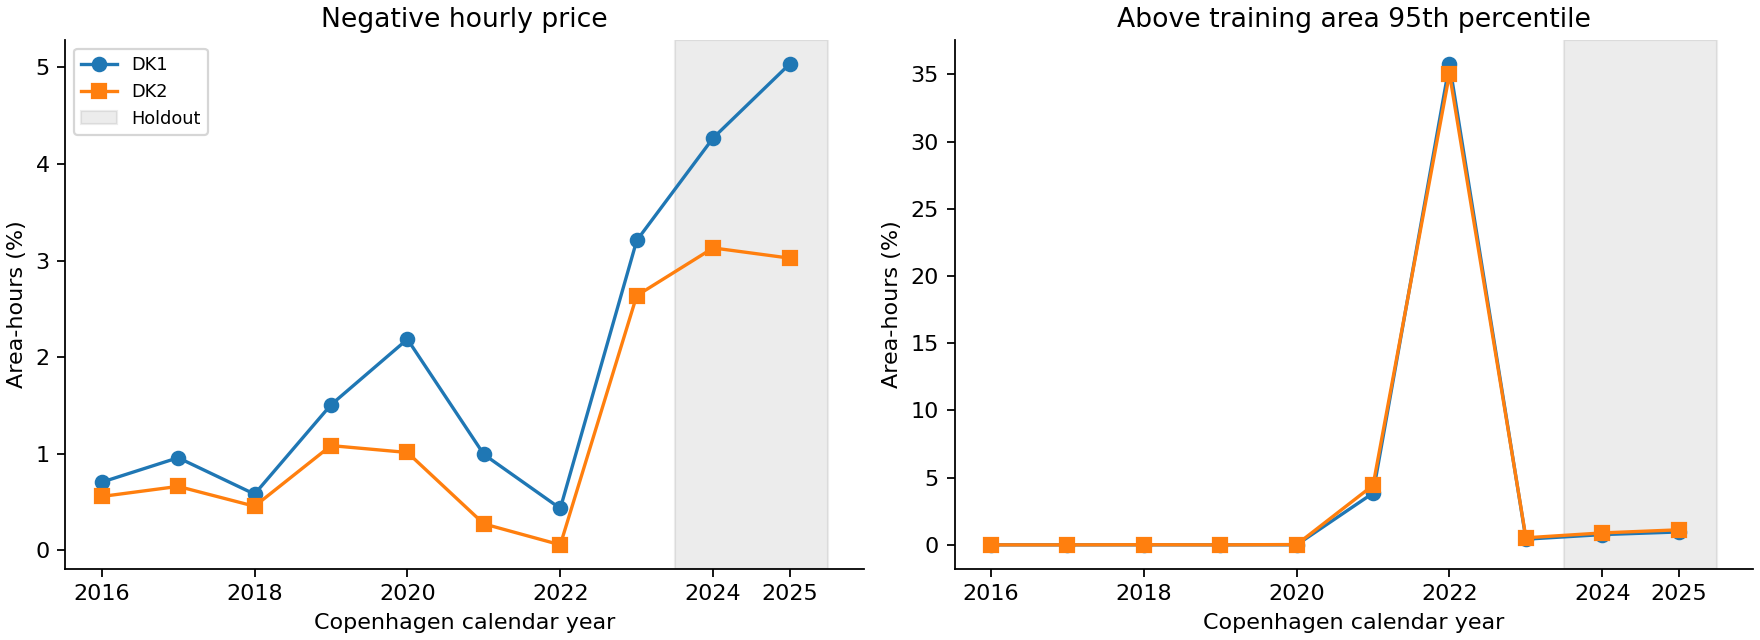

,year,PriceArea,n,negative_events,high_events,negative_rate,high_rate
0,2016,DK1,8784,62,0,0.007058,0.000000
1,2016,DK2,8784,49,0,0.005578,0.000000
2,2017,DK1,8760,84,0,0.009589,0.000000
3,2017,DK2,8760,58,0,0.006621,0.000000
4,2018,DK1,8760,51,0,0.005822,0.000000
5,2018,DK2,8760,40,1,0.004566,0.000114
6,2019,DK1,8760,132,0,0.015068,0.000000
7,2019,DK2,8760,95,0,0.010845,0.000000
8,2020,DK1,8784,192,0,0.021858,0.000000
9,2020,DK2,8784,89,2,0.010132,0.000228


In [4]:
display(Image(filename=str(RESULTS/'figures/yearly_events.png')))
display(pd.read_csv(RESULTS/'event_rates.csv'))

### Clustering and distribution drift
K-means and GMM fit all eight training years. DBSCAN fits a bounded stratified sample from every training year/area; its frozen nearest-core adapter leaves out-of-neighborhood points as noise. Cluster IDs have meaning only within each method.

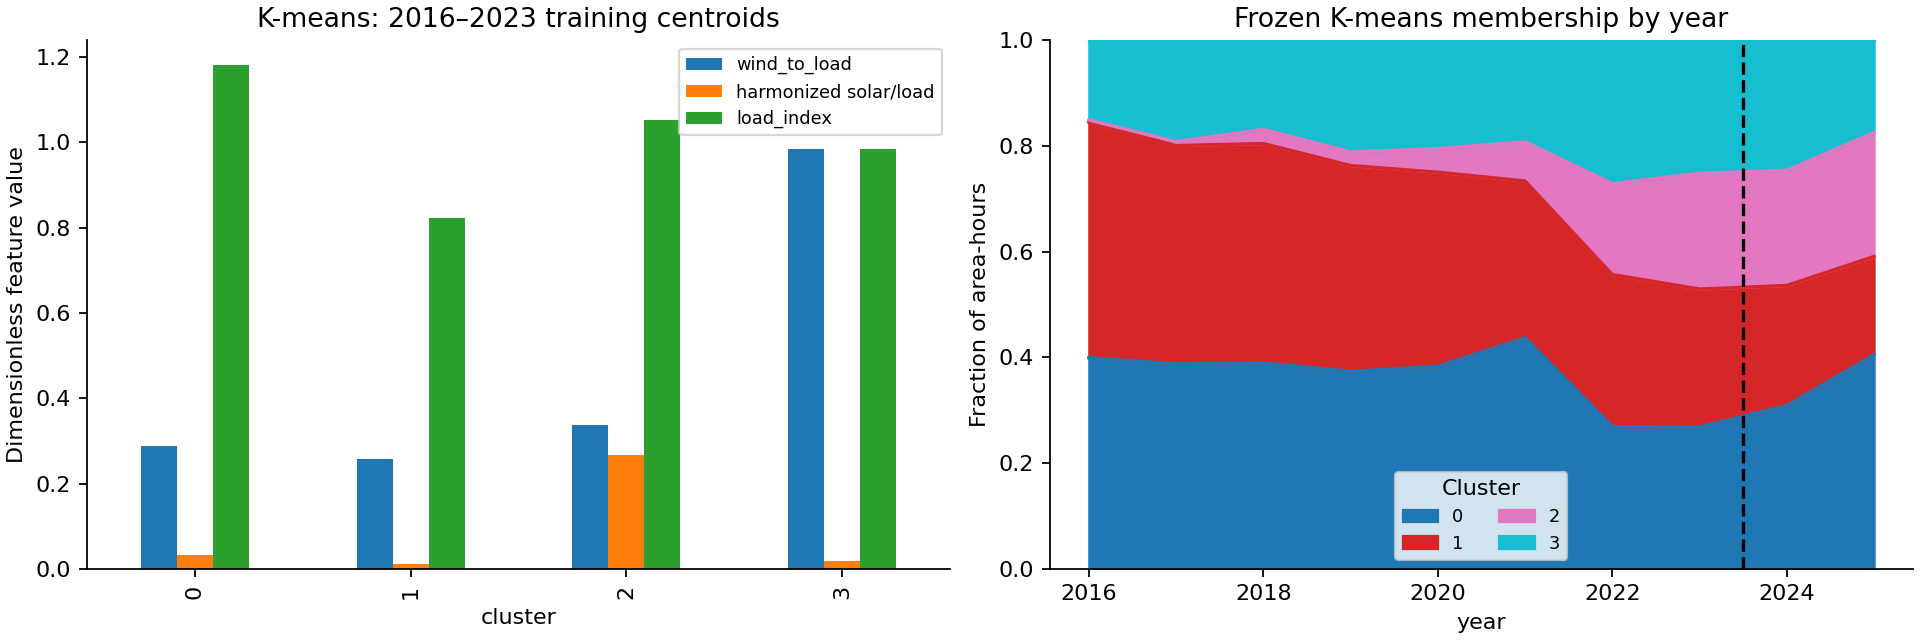

,method,split,n,clusters,noise_fraction,silhouette,davies_bouldin
0,kmeans,train,140256,4,0.000000,0.355737,0.917716
1,kmeans,test,35088,4,0.000000,0.310662,0.983649
2,gmm,train,140256,7,0.000000,0.023916,2.639190
3,gmm,test,35088,7,0.000000,0.029460,3.929847
4,dbscan,train,140256,9,0.262784,-0.115347,1.257723
5,dbscan,test,35088,9,0.458162,-0.300390,1.413481


,method,parameter,bic,converged,min_cluster_fraction,noise_fraction,k_distance_quantile,sample_rows,clusters,silhouette
0,gmm,3.000000,487506.115908,True,0.231648,0.00000,NaN,NaN,NaN,NaN
1,gmm,4.000000,453476.305476,True,0.120601,0.00000,NaN,NaN,NaN,NaN
2,gmm,5.000000,438157.705820,True,0.100338,0.00000,NaN,NaN,NaN,NaN
3,gmm,6.000000,427424.895431,True,0.057309,0.00000,NaN,NaN,NaN,NaN
4,gmm,7.000000,405842.962740,True,0.056254,0.00000,NaN,NaN,NaN,NaN
5,dbscan,0.157696,NaN,NaN,NaN,0.25695,0.65,20000.0,9.0,-0.332047
6,dbscan,0.220479,NaN,NaN,NaN,0.14250,0.80,20000.0,2.0,NaN
7,dbscan,0.428070,NaN,NaN,NaN,0.02570,0.95,20000.0,2.0,NaN


In [5]:
display(Image(filename=str(RESULTS/'figures/clusters_and_drift.png')))
display(pd.read_csv(RESULTS/'cluster_metrics.csv'))
display(pd.read_csv(RESULTS/'additional_clustering_candidates.csv'))

### Classification: probability quality and rare-event discrimination
Compare energy+calendar models with calendar-only models of the same family. Brier is lower-is-better; average precision should be compared with event prevalence. Scores are also separated by test year and price area.

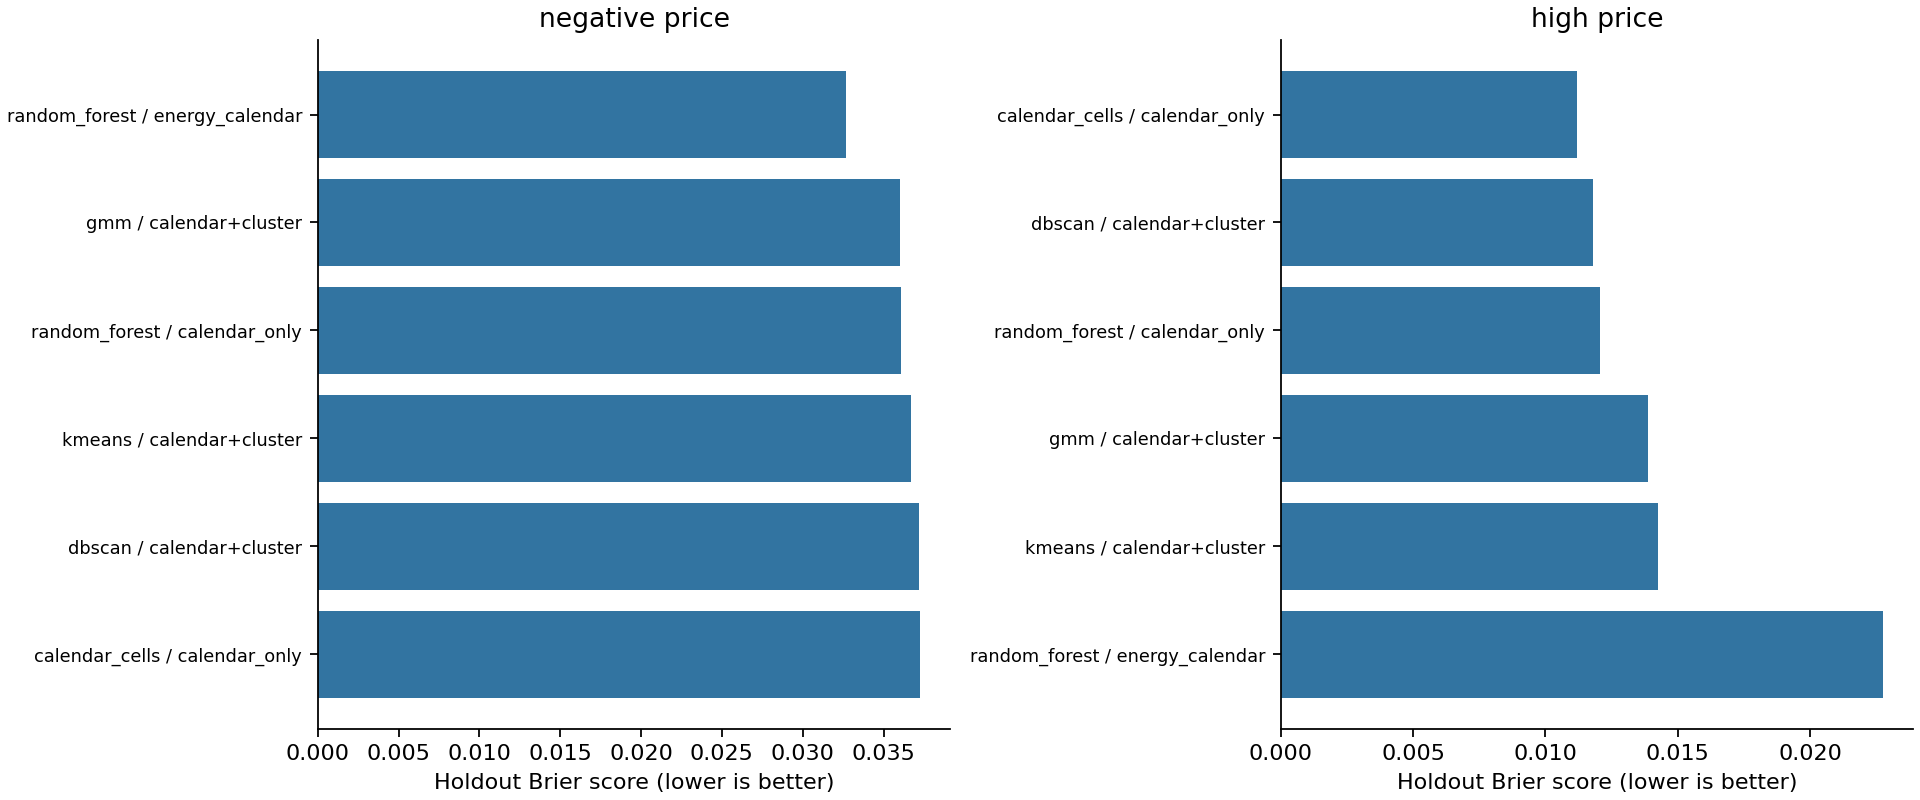

,method,features,event,n,events,base_rate,brier,average_precision,roc_auc
0,calendar_cells,calendar_only,negative_price,35088,1356,0.038646,0.037271,0.101507,0.765025
7,kmeans,calendar+cluster,negative_price,35088,1356,0.038646,0.036725,0.105586,0.773557
14,gmm,calendar+cluster,negative_price,35088,1356,0.038646,0.036030,0.170861,0.818562
21,dbscan,calendar+cluster,negative_price,35088,1356,0.038646,0.037165,0.136538,0.817294
28,calendar_cells,calendar_only,high_price,35088,327,0.009319,0.011208,0.012916,0.619374
35,kmeans,calendar+cluster,high_price,35088,327,0.009319,0.014262,0.011906,0.626104
42,gmm,calendar+cluster,high_price,35088,327,0.009319,0.013891,0.013200,0.645263
49,dbscan,calendar+cluster,high_price,35088,327,0.009319,0.011784,0.012392,0.588671
56,random_forest,calendar_only,negative_price,35088,1356,0.038646,0.036060,0.193103,0.785346
63,random_forest,energy_calendar,negative_price,35088,1356,0.038646,0.032687,0.223000,0.832064


,features,event,test_year,brier,average_precision
56,calendar_only,negative_price,2024-2025,0.036060,0.193103
57,calendar_only,negative_price,2024,0.034401,0.200154
60,calendar_only,negative_price,2025,0.037725,0.188305
63,energy_calendar,negative_price,2024-2025,0.032687,0.223000
64,energy_calendar,negative_price,2024,0.030953,0.253661
67,energy_calendar,negative_price,2025,0.034425,0.203003
70,calendar_only,high_price,2024-2025,0.012078,0.041465
71,calendar_only,high_price,2024,0.010872,0.060058
74,calendar_only,high_price,2025,0.013286,0.030900
77,energy_calendar,high_price,2024-2025,0.022764,0.017323


In [6]:
display(Image(filename=str(RESULTS/'figures/classification_comparison.png')))
classification = pd.read_csv(RESULTS/'classification_metrics.csv')
display(classification[(classification.test_year=='2024-2025') & (classification.area=='both')][['method','features','event','n','events','base_rate','brier','average_precision','roc_auc']])
display(classification[(classification.method=='random_forest') & (classification.area=='both')][['features','event','test_year','brier','average_precision']])

### Price regression
MAE and RMSE are EUR/MWh. The boosting model has fixed hyperparameters with no random internal validation or holdout tuning.

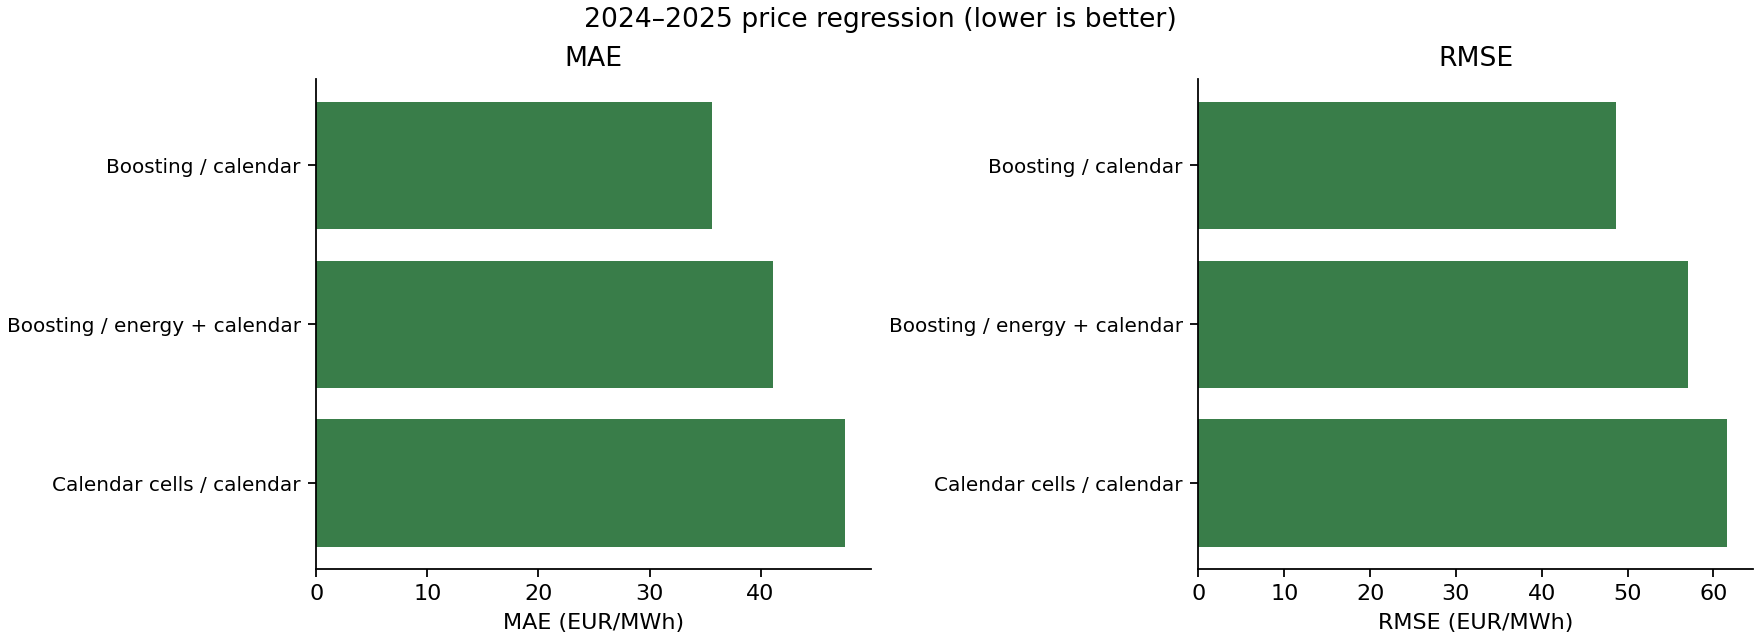

,method,features,test_year,area,n,mae_eur_mwh,rmse_eur_mwh,mean_error_eur_mwh
0,calendar_cells,calendar_only,2024-2025,both,35088,47.581685,61.582269,-35.318135
1,calendar_cells,calendar_only,2024,both,17568,42.252072,58.244484,-29.805131
4,calendar_cells,calendar_only,2025,both,17520,52.925899,64.756680,-40.846243
7,gradient_boosting,calendar_only,2024-2025,both,35088,35.650682,48.623254,-6.905398
8,gradient_boosting,calendar_only,2024,both,17568,32.373970,46.376090,-1.426251
11,gradient_boosting,calendar_only,2025,both,17520,38.936371,50.776814,-12.399556
14,gradient_boosting,energy_calendar,2024-2025,both,35088,41.119945,57.054559,18.247738
15,gradient_boosting,energy_calendar,2024,both,17568,38.704074,55.327157,23.745170
18,gradient_boosting,energy_calendar,2025,both,17520,43.542435,58.735704,12.735244


,method,target,loss,improvement,ci_low,ci_high,repeats,block_days
0,random_forest,negative_price,Brier,0.003374,0.001885,0.005136,400,7
1,random_forest,high_price,Brier,-0.010686,-0.012919,-0.008790,400,7
2,gradient_boosting,SpotPriceEUR,MAE EUR/MWh,-5.469263,-8.429448,-2.223808,400,7


In [7]:
display(Image(filename=str(RESULTS/'figures/regression_comparison.png')))
regression = pd.read_csv(RESULTS/'regression_metrics.csv')
display(regression[regression.area=='both'])
display(pd.read_csv(RESULTS/'paired_improvement_intervals.csv'))

### Apriori transfer and uncertainty
Rules are mined only from predictor baskets, selected on training counts and lift, and then frozen. Exploratory intervals resample consecutive seven-day blocks synchronously across areas.

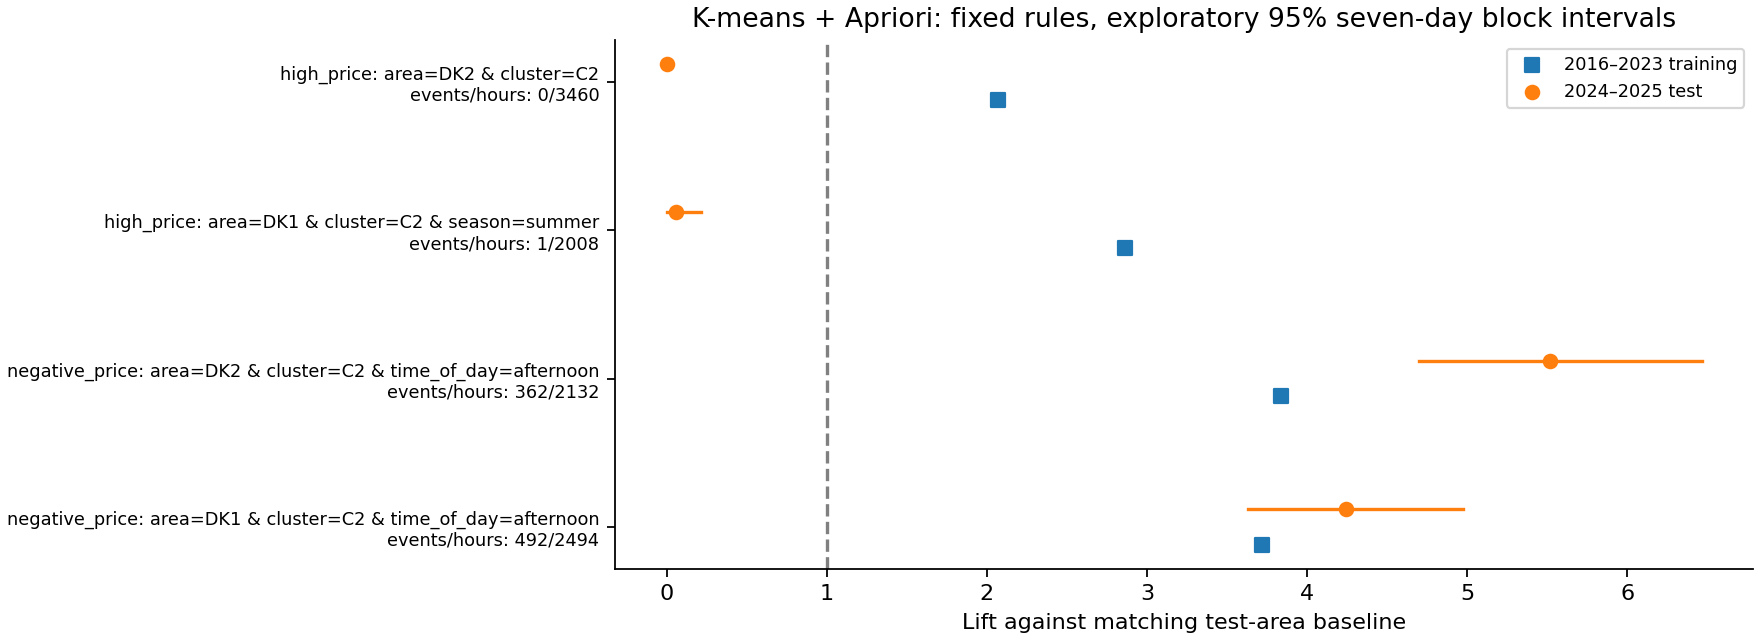

,method,event,antecedent,train_n,train_events,train_lift,test_n,test_events,test_lift,ci_low,ci_high,test_small_sample
0,kmeans,negative_price,area=DK1 & cluster=C2 & time_of_day=afternoon,3947.0,194.0,3.718316,2494.0,492.0,4.241379,3.634090,4.975895,False
1,kmeans,negative_price,area=DK2 & cluster=C2 & time_of_day=afternoon,2845.0,92.0,3.837157,2132.0,362.0,5.516406,4.700736,6.464021,False
2,kmeans,high_price,area=DK1 & cluster=C2 & season=summer,2821.0,404.0,2.863743,2008.0,1.0,0.057861,0.000000,0.216192,True
3,kmeans,high_price,area=DK2 & cluster=C2,4105.0,425.0,2.070291,3460.0,0.0,0.000000,0.000000,0.000000,True
4,gmm,negative_price,area=DK1 & cluster=C5 & time_of_day=afternoon,3600.0,223.0,4.686127,2506.0,500.0,4.289705,3.713260,5.021565,False
5,gmm,negative_price,area=DK2 & cluster=C0 & demand=low,7687.0,274.0,4.229584,1336.0,18.0,0.437725,0.102400,0.845442,True
6,gmm,high_price,area=DK1 & cluster=C5,5324.0,497.0,1.866698,4445.0,1.0,0.026138,0.000000,0.095374,True
7,gmm,high_price,area=DK2 & cluster=C6 & season=summer,4006.0,340.0,1.697163,700.0,1.0,0.142403,0.000000,0.529303,True
8,dbscan,negative_price,area=DK1 & cluster=C-1 & demand=mid,7900.0,256.0,2.451459,1566.0,37.0,0.507982,0.265571,0.766495,False
9,dbscan,negative_price,area=DK2 & cluster=C-1 & demand=mid,6239.0,148.0,2.814820,1449.0,178.0,3.991044,2.956054,5.242728,False


,method,event,antecedent,year,n,events,support,joint_support,confidence,base_rate,lift,small_sample
0,kmeans,negative_price,area=DK1 & cluster=C2 & time_of_day=afternoon,2024,1201.0,215.0,0.068363,0.012238,0.179017,0.042691,4.193306,False
1,kmeans,negative_price,area=DK1 & cluster=C2 & time_of_day=afternoon,2025,1293.0,277.0,0.073801,0.015811,0.214230,0.050342,4.255462,False
2,kmeans,negative_price,area=DK2 & cluster=C2 & time_of_day=afternoon,2024,1043.0,175.0,0.059369,0.009961,0.167785,0.031307,5.359365,False
3,kmeans,negative_price,area=DK2 & cluster=C2 & time_of_day=afternoon,2025,1089.0,187.0,0.062158,0.010674,0.171717,0.030251,5.676387,False
4,kmeans,high_price,area=DK1 & cluster=C2 & season=summer,2024,967.0,0.0,0.055043,0.000000,0.000000,0.007628,0.000000,True
5,kmeans,high_price,area=DK1 & cluster=C2 & season=summer,2025,1041.0,1.0,0.059418,0.000057,0.000961,0.009589,0.100178,True
6,kmeans,high_price,area=DK2 & cluster=C2,2024,1704.0,0.0,0.096995,0.000000,0.000000,0.008880,0.000000,True
7,kmeans,high_price,area=DK2 & cluster=C2,2025,1756.0,0.0,0.100228,0.000000,0.000000,0.011187,0.000000,True
8,gmm,negative_price,area=DK1 & cluster=C5 & time_of_day=afternoon,2024,1202.0,220.0,0.068420,0.012523,0.183028,0.042691,4.287255,False
9,gmm,negative_price,area=DK1 & cluster=C5 & time_of_day=afternoon,2025,1304.0,280.0,0.074429,0.015982,0.214724,0.050342,4.265264,False


In [8]:
display(Image(filename=str(RESULTS/'figures/frozen_rules.png')))
rules = pd.read_csv(RESULTS/'selected_rules.csv')
display(rules[['method','event','antecedent','train_n','train_events','train_lift','test_n','test_events','test_lift','ci_low','ci_high','test_small_sample']])
display(pd.read_csv(RESULTS/'rule_by_test_year.csv'))

### Solar-definition and correction sensitivities
The primary target definitions and test population remain fixed. One sensitivity removes solar; another fits the clustering only on rows that never required a negative-estimate correction. No hidden zero imputation of missing observations is used.

In [9]:
sensitivity = pd.read_csv(RESULTS/'solar_break_sensitivity.csv')
display(sensitivity[(sensitivity.test_year=='2024-2025') & (sensitivity.area=='both')])

,method,features,event,test_year,area,n,events,base_rate,brier,average_precision,roc_auc,precision_at_0_5,recall_at_0_5
0,kmeans_without_solar,calendar+cluster,negative_price,2024-2025,both,35088,1356,0.038646,0.037600,0.079733,0.720197,0.0,0.0
7,kmeans_without_solar,calendar+cluster,high_price,2024-2025,both,35088,327,0.009319,0.011617,0.017083,0.702528,0.0,0.0
14,kmeans_strict_no_solar_repair,calendar+cluster,negative_price,2024-2025,both,35088,1356,0.038646,0.036723,0.106045,0.774178,0.0,0.0
21,kmeans_strict_no_solar_repair,calendar+cluster,high_price,2024-2025,both,35088,327,0.009319,0.014334,0.012015,0.629302,0.0,0.0


## Takeaways
The report below is generated from the executed study. Read yearly/area scores, rare-event denominators, historical corrections and paired intervals before interpreting a pooled winner.

In [10]:
display(Markdown((RESULTS/'pilot_findings.md').read_text(encoding='utf-8')))

# Ten-year pilot findings



**Training: 2016–2023 (eight years). Test: 2024–2025 (two later years).**

The latest ten completed calendar years as of November 1, 2026 are 2016–2025. Source coverage is checked before fitting; no random train/test split is used.



Usable training area-hours: 140,256; test area-hours: 35,088.



## Main reading



Random Forest negative-event Brier improves from 0.036060 (calendar only) to 0.032687 (energy + calendar), a 9.4% relative reduction. High-event Brier worsens from 0.012078 to 0.022764. The paired intervals below quantify those changes.

Gradient-boosting MAE changes from 35.65 to 41.12 EUR/MWh when energy features are added. More realized-energy inputs do not uniformly improve out-of-time performance.

The fixed K-means afternoon/solar-rich negative-price rules have pooled test lifts area=DK1: 4.24 (492/2494 events/hours), area=DK2: 5.52 (362/2132 events/hours). See rule_by_test_year.csv for each year separately.

88.4% of training high-price events occur in 2022. Their pooled test prevalence is only 0.93%, versus about 5% in pooled training by definition. This documents a substantial target-distribution shift; it does not identify a causal explanation.

All methods use realized settlement generation/load. Classifiers and regressors are retrospective conditional models, **not operational day-ahead forecasts**. The 2024 period was already examined in the original pilot, so this is exploratory temporal evaluation, not an untouched confirmatory holdout.



## Data compatibility



Before 2020, the source places all solar in SolarPowerSelfConMWh. From 2020, total reported solar is grid components plus estimated self-consumption. The decade uses this **reported total solar proxy**, not a fictitious pre-2020 grid-solar series. Metadata warns of a measurement/layout break and uncertain gross-consumption accounting. See the separate wind/load-only sensitivity and annual profiles.

The 2020 data contain 1,747 negative estimated self-use values, despite the metadata definition max(modeled production minus actual, 0). The harmonized feature applies that stated nonnegative bound, preserves the original signed values and flags all repairs. This is a documented repair assumption, not zero-filling missing observations. A separate strict clustering sensitivity excludes every repaired row and still represents all eight training years; event definitions and the test population stay fixed.

From October 1, 2025, four complete 15-minute prices are averaged to EUR/MWh per hour. Negative/high events then concern the hourly mean; a negative quarter need not make its hourly mean negative. Exact quarter counts, original responses and the transition audit are retained. Prices are not summed.



## Event counts and fixed thresholds



| year | PriceArea | n | negative_events | high_events | negative_rate | high_rate |
| --- | --- | --- | --- | --- | --- | --- |
| 2016 | DK1 | 8784 | 62 | 0 | 0.0071 | 0.0000 |
| 2016 | DK2 | 8784 | 49 | 0 | 0.0056 | 0.0000 |
| 2017 | DK1 | 8760 | 84 | 0 | 0.0096 | 0.0000 |
| 2017 | DK2 | 8760 | 58 | 0 | 0.0066 | 0.0000 |
| 2018 | DK1 | 8760 | 51 | 0 | 0.0058 | 0.0000 |
| 2018 | DK2 | 8760 | 40 | 1 | 0.0046 | 0.0001 |
| 2019 | DK1 | 8760 | 132 | 0 | 0.0151 | 0.0000 |
| 2019 | DK2 | 8760 | 95 | 0 | 0.0108 | 0.0000 |
| 2020 | DK1 | 8784 | 192 | 0 | 0.0219 | 0.0000 |
| 2020 | DK2 | 8784 | 89 | 2 | 0.0101 | 0.0002 |
| 2021 | DK1 | 8760 | 87 | 337 | 0.0099 | 0.0385 |
| 2021 | DK2 | 8760 | 24 | 388 | 0.0027 | 0.0443 |
| 2022 | DK1 | 8760 | 38 | 3133 | 0.0043 | 0.3576 |
| 2022 | DK2 | 8760 | 5 | 3070 | 0.0006 | 0.3505 |
| 2023 | DK1 | 8760 | 281 | 37 | 0.0321 | 0.0042 |
| 2023 | DK2 | 8760 | 231 | 46 | 0.0264 | 0.0053 |
| 2024 | DK1 | 8784 | 375 | 67 | 0.0427 | 0.0076 |
| 2024 | DK2 | 8784 | 275 | 78 | 0.0313 | 0.0089 |
| 2025 | DK1 | 8760 | 441 | 84 | 0.0503 | 0.0096 |
| 2025 | DK2 | 8760 | 265 | 98 | 0.0303 | 0.0112 |



High-price thresholds are the area-specific pooled 2016–2023 95th percentiles, held fixed for both test years. This differs from the original 2023-only threshold.



## Unsupervised methods



| method | split | n | clusters | noise_fraction | silhouette | davies_bouldin |
| --- | --- | --- | --- | --- | --- | --- |
| kmeans | train | 140256 | 4 | 0.0000 | 0.3557 | 0.9177 |
| kmeans | test | 35088 | 4 | 0.0000 | 0.3107 | 0.9836 |
| gmm | train | 140256 | 7 | 0.0000 | 0.0239 | 2.6392 |
| gmm | test | 35088 | 7 | 0.0000 | 0.0295 | 3.9298 |
| dbscan | train | 140256 | 9 | 0.2628 | -0.1153 | 1.2577 |
| dbscan | test | 35088 | 9 | 0.4582 | -0.3004 | 1.4135 |

K-means uses k=3..7, training-only standardization, silhouette and a 3% smallest-cluster guard. GMM selects among 3..7 full-covariance mixtures by training BIC, convergence and the same size guard. DBSCAN fits a deterministic <=20,000-row year/area-stratified training sample; every training/test row is assigned via frozen core neighborhoods. This is a bounded pilot approximation, not a native DBSCAN predict operation. Noise remains -1.



## Classification: temporal holdout



| method | features | event | n | events | brier | average_precision | roc_auc |
| --- | --- | --- | --- | --- | --- | --- | --- |
| calendar_cells | calendar_only | negative_price | 35088 | 1356 | 0.0373 | 0.1015 | 0.7650 |
| kmeans | calendar+cluster | negative_price | 35088 | 1356 | 0.0367 | 0.1056 | 0.7736 |
| gmm | calendar+cluster | negative_price | 35088 | 1356 | 0.0360 | 0.1709 | 0.8186 |
| dbscan | calendar+cluster | negative_price | 35088 | 1356 | 0.0372 | 0.1365 | 0.8173 |
| calendar_cells | calendar_only | high_price | 35088 | 327 | 0.0112 | 0.0129 | 0.6194 |
| kmeans | calendar+cluster | high_price | 35088 | 327 | 0.0143 | 0.0119 | 0.6261 |
| gmm | calendar+cluster | high_price | 35088 | 327 | 0.0139 | 0.0132 | 0.6453 |
| dbscan | calendar+cluster | high_price | 35088 | 327 | 0.0118 | 0.0124 | 0.5887 |
| random_forest | calendar_only | negative_price | 35088 | 1356 | 0.0361 | 0.1931 | 0.7853 |
| random_forest | energy_calendar | negative_price | 35088 | 1356 | 0.0327 | 0.2230 | 0.8321 |
| random_forest | calendar_only | high_price | 35088 | 327 | 0.0121 | 0.0415 | 0.7751 |
| random_forest | energy_calendar | high_price | 35088 | 327 | 0.0228 | 0.0173 | 0.7015 |

Lower Brier is better. Average precision should be read against the event prevalence; ROC-AUC alone can hide rare-event weakness. Full per-year/area results and fixed-0.5 precision/recall are in classification_metrics.csv. Cluster probability cells and all calendar backoffs use training outcomes only.



## Price regression: temporal holdout



| method | features | n | mae_eur_mwh | rmse_eur_mwh | mean_error_eur_mwh |
| --- | --- | --- | --- | --- | --- |
| calendar_cells | calendar_only | 35088 | 47.5817 | 61.5823 | -35.3181 |
| gradient_boosting | calendar_only | 35088 | 35.6507 | 48.6233 | -6.9054 |
| gradient_boosting | energy_calendar | 35088 | 41.1199 | 57.0546 | 18.2477 |

MAE/RMSE are EUR/MWh; smaller is better. HistGradientBoostingRegressor uses fixed hyperparameters and early_stopping=False, avoiding random internal validation. No holdout target is used in fitting or selection.



## Paired energy-versus-calendar comparisons



| method | target | loss | improvement | ci_low | ci_high | repeats | block_days |
| --- | --- | --- | --- | --- | --- | --- | --- |
| random_forest | negative_price | Brier | 0.0034 | 0.0019 | 0.0051 | 400 | 7 |
| random_forest | high_price | Brier | -0.0107 | -0.0129 | -0.0088 | 400 | 7 |
| gradient_boosting | SpotPriceEUR | MAE EUR/MWh | -5.4693 | -8.4294 | -2.2238 | 400 | 7 |

Positive improvement means adding realized energy features lowers loss against the same model family using calendar features alone. Intervals use paired seven-day moving blocks of the test period, preserving both areas and serial dependence. These exploratory intervals do not account for trying multiple model families.



## Solar-definition and correction sensitivity



| method | event | n | events | brier | average_precision |
| --- | --- | --- | --- | --- | --- |
| kmeans_without_solar | negative_price | 35088 | 1356 | 0.0376 | 0.0797 |
| kmeans_without_solar | high_price | 35088 | 327 | 0.0116 | 0.0171 |
| kmeans_strict_no_solar_repair | negative_price | 35088 | 1356 | 0.0367 | 0.1060 |
| kmeans_strict_no_solar_repair | high_price | 35088 | 327 | 0.0143 | 0.0120 |

The no-solar variant removes the measurement bridge entirely. The strict-no-repair variant retains only original nonnegative estimates in training, using the fixed primary event definitions and the same two test years. Differences are reported, not used to retune the primary models.



## Apriori rules for the three clustering methods



| method | event | antecedent | train_lift | test_events/hours | test_lift | ci_low | ci_high | test_small_sample |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| kmeans | negative_price | area=DK1 & cluster=C2 & time_of_day=afternoon | 3.7183 | 492/2494 | 4.2414 | 3.6341 | 4.9759 | False |
| kmeans | negative_price | area=DK2 & cluster=C2 & time_of_day=afternoon | 3.8372 | 362/2132 | 5.5164 | 4.7007 | 6.4640 | False |
| kmeans | high_price | area=DK1 & cluster=C2 & season=summer | 2.8637 | 1/2008 | 0.0579 | 0.0000 | 0.2162 | True |
| kmeans | high_price | area=DK2 & cluster=C2 | 2.0703 | 0/3460 | 0.0000 | 0.0000 | 0.0000 | True |
| gmm | negative_price | area=DK1 & cluster=C5 & time_of_day=afternoon | 4.6861 | 500/2506 | 4.2897 | 3.7133 | 5.0216 | False |
| gmm | negative_price | area=DK2 & cluster=C0 & demand=low | 4.2296 | 18/1336 | 0.4377 | 0.1024 | 0.8454 | True |
| gmm | high_price | area=DK1 & cluster=C5 | 1.8667 | 1/4445 | 0.0261 | 0.0000 | 0.0954 | True |
| gmm | high_price | area=DK2 & cluster=C6 & season=summer | 1.6972 | 1/700 | 0.1424 | 0.0000 | 0.5293 | True |
| dbscan | negative_price | area=DK1 & cluster=C-1 & demand=mid | 2.4515 | 37/1566 | 0.5080 | 0.2656 | 0.7665 | False |
| dbscan | negative_price | area=DK2 & cluster=C-1 & demand=mid | 2.8148 | 178/1449 | 3.9910 | 2.9561 | 5.2427 | False |
| dbscan | high_price | area=DK1 & cluster=C-1 & season=summer | 1.5961 | 2/2766 | 0.0840 | 0.0000 | 0.2192 | True |
| dbscan | high_price | area=DK2 & cluster=C-1 & season=summer | 1.7313 | 0/2370 | 0.0000 | 0.0000 | 0.0000 | True |

Predictor-only Apriori retains rare outcomes. At most one training-selected rule per area/event/method; >=2% antecedent support, >=100 hours and >=20 events. Rules are frozen before holdout scoring. Year-specific counts/lifts are in rule_by_test_year.csv; do not treat pooled two-year enrichment as stability in each year.

A rule with zero observed test events can have a degenerate [0,0] empirical bootstrap interval. This does not show that its future event probability is zero; small-sample flags and exact counts take priority over an apparently narrow interval.



## Limits and next iteration



Ten years span major market and measurement changes. Pooled thresholds, capacity growth and distribution drift can change event prevalence; no installed-capacity normalization, weather, fuel or interconnector features are added. No causal claim is supported. Cluster IDs are method-specific. DBSCAN separation failure or high noise is a result, not a reason to tune against the test set.

1. Inspect 2020 solar-definition and 2025 interval-transition sensitivity before substantive interpretation.

2. Check year/area scores and paired intervals rather than selecting the best pooled test score for retuning.

3. If building a forecasting study later, obtain genuinely pre-clearing predictors and reserve a new untouched period.



Source: Energinet Energi Data Service, CC BY 4.0. Official metadata, raw selected-field responses and derived data are bundled with the study.
